In [2]:
import orbitize
import numpy as np
import matplotlib.pyplot as plt
import astropy
from pathlib import Path
import pandas as pd
from astropy import units as u
import matplotlib.pyplot as plt
import numpy as np
from astropy.time import Time
from astropy.table import Table
from orbitize import gaia
rng = np.random.default_rng(90)
from orbitize import read_input, plot, priors, system, sampler, DATADIR

In [3]:

# import Eps Eri RVs from Sarah
rv_file = (
    Path.home()
    / "Projects"
    / "roman-orbits"
    / "all_fits"
    / "eps_Eri"
    / "data"
    / "22049_rv_orbitize.csv"
)

data_table = read_input.read_file(rv_file)

print(data_table.colnames)
data_table[:5]

['epoch', 'object', 'quant1', 'quant1_err', 'quant2', 'quant2_err', 'quant12_corr', 'quant_type', 'instrument']


epoch,object,quant1,quant1_err,quant2,quant2_err,quant12_corr,quant_type,instrument
float64,int64,float64,float64,float64,float64,float64,bytes5,str20
47046.469072056934,0,0.00242842434397,0.00355849933787,nan,nan,nan,rv,Hamilton
47047.42989999987,0,0.0168436519401,0.008402184,nan,nan,nan,rv,Hamilton
47048.41275998764,0,3.72850080874e-05,0.00565189657901,nan,nan,nan,rv,Hamilton
47093.353567025624,0,-0.022588233913,0.00655259349236,nan,nan,nan,rv,Hamilton
47149.34010240482,0,0.00533195998066,0.00688978051146,nan,nan,nan,rv,Hamilton


693 RVs from 9 instruments
Time baseline: 33.2 years
Instruments: CES-LC, CES-VLC, EXPRES, HARPS-post, HARPS-pre, HIRES-post, Hamilton, Levy, Tull


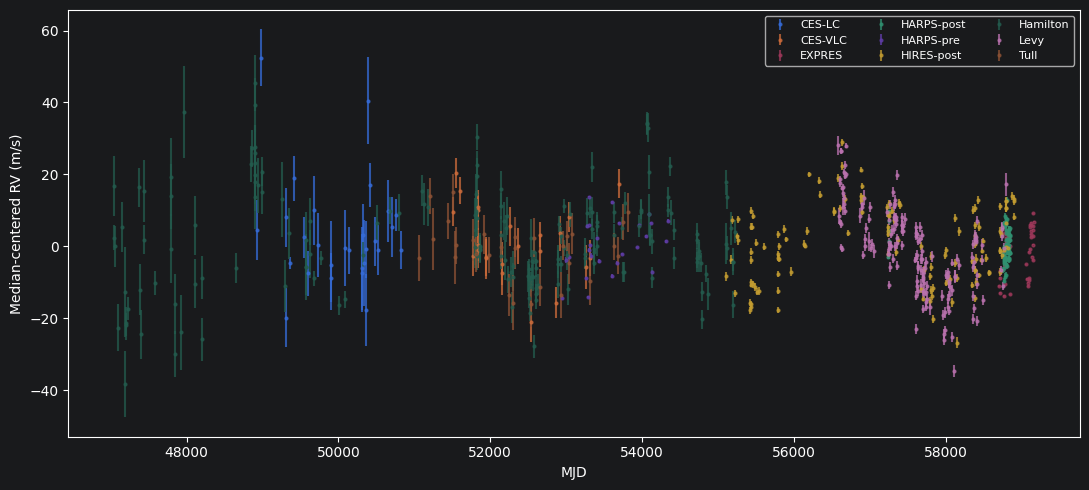

In [4]:
# Plot RVs

instruments = np.unique(data_table["instrument"])
baseline_years = np.ptp(data_table["epoch"]) / 365.25
print(f"{len(data_table)} RVs from {len(instruments)} instruments")
print(f"Time baseline: {baseline_years:.1f} years")
print("Instruments:", ", ".join(instruments))

fig, ax = plt.subplots(figsize=(11, 5))
for instrument in instruments:
    use = data_table["instrument"] == instrument
    ax.errorbar(
        data_table["epoch"][use],
        1_000 * data_table["quant1"][use],
        yerr=1_000 * data_table["quant1_err"][use],
        fmt=".",
        ms=4,
        alpha=0.75,
        label=instrument,
    )
ax.set(xlabel="MJD", ylabel="Median-centered RV (m/s)")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()

In [5]:
# CREATE SYSTEM
# system parameters
num_secondary_bodies = 1
stellar_mass = 0.82 # [Msol]
plx = 310.577 # [mas]
mass_err = 0.02 # [Msol]
plx_err = 0.135 # [mas]

# MCMC parameters
num_temps = 10
num_walkers = 128
num_threads = 10
burn_steps = 2_000
num_steps = 5_000
thin = 1
tau_ref_epoch = 58_849  # MJD (2020-01-01)

my_system = system.System(
    num_secondary_bodies,
    data_table,
    stellar_mass,
    plx,
    mass_err=mass_err,
    plx_err=plx_err,
    fit_secondary_mass=True,
    tau_ref_epoch=tau_ref_epoch,
    fitting_basis="SemiAmp",
)

In [6]:
print(f"Number of parameters: {len(my_system.labels)}")
print(my_system.labels)

Number of parameters: 27
['per1', 'ecc1', 'inc1', 'aop1', 'pan1', 'tau1', 'K1', 'plx', 'gamma_CES-LC', 'sigma_CES-LC', 'gamma_CES-VLC', 'sigma_CES-VLC', 'gamma_EXPRES', 'sigma_EXPRES', 'gamma_HARPS-post', 'sigma_HARPS-post', 'gamma_HARPS-pre', 'sigma_HARPS-pre', 'gamma_HIRES-post', 'sigma_HIRES-post', 'gamma_Hamilton', 'sigma_Hamilton', 'gamma_Levy', 'sigma_Levy', 'gamma_Tull', 'sigma_Tull', 'm0']


In [7]:
# set up priors

idx = my_system.param_idx
# Orbital priors
my_system.sys_priors[idx["per1"]] = priors.UniformPrior(5.0, 10.0)       # years
my_system.sys_priors[idx["ecc1"]] = priors.UniformPrior(0.0, 0.99)
my_system.sys_priors[idx["K1"]] = priors.LogUniformPrior(0.001, 0.05)    # km/s

# RV only data do not constrain orientation
my_system.sys_priors[idx["inc1"]] = priors.SinPrior()
my_system.sys_priors[idx["pan1"]] = priors.UniformPrior(0, 2 * np.pi)

# One velocity offset and jitter per instrument
for instrument in my_system.rv_instruments:
    my_system.sys_priors[idx[f"gamma_{instrument}"]] = (
        priors.UniformPrior(-0.1, 0.1)
    )
    my_system.sys_priors[idx[f"sigma_{instrument}"]] = (
        priors.LogUniformPrior(1e-4, 0.05)
    )

In [8]:
# SUMMON THE SAMPLER!
m = sampler.MCMC(
    my_system,
    num_temps=num_temps,
    num_walkers=num_walkers,
    num_threads=num_threads,
)

In [9]:
# run sampler
run = m.run_sampler(
    num_walkers * num_steps,
    burn_steps=burn_steps,
)

print(f"Posterior samples: {len(m.results.post)}")
print(f"Mean acceptance fraction: {np.mean(run.acceptance_fraction):.3f}")

Starting Burn in


/Users/clary/Projects/orbitize/orbitize/priors.py:568: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:568: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarn

2000/2000 steps of burn-in complete
Burn in complete. Sampling posterior now.
5000/5000 steps completed
Run complete
Posterior samples: 640000
Mean acceptance fraction: 0.142


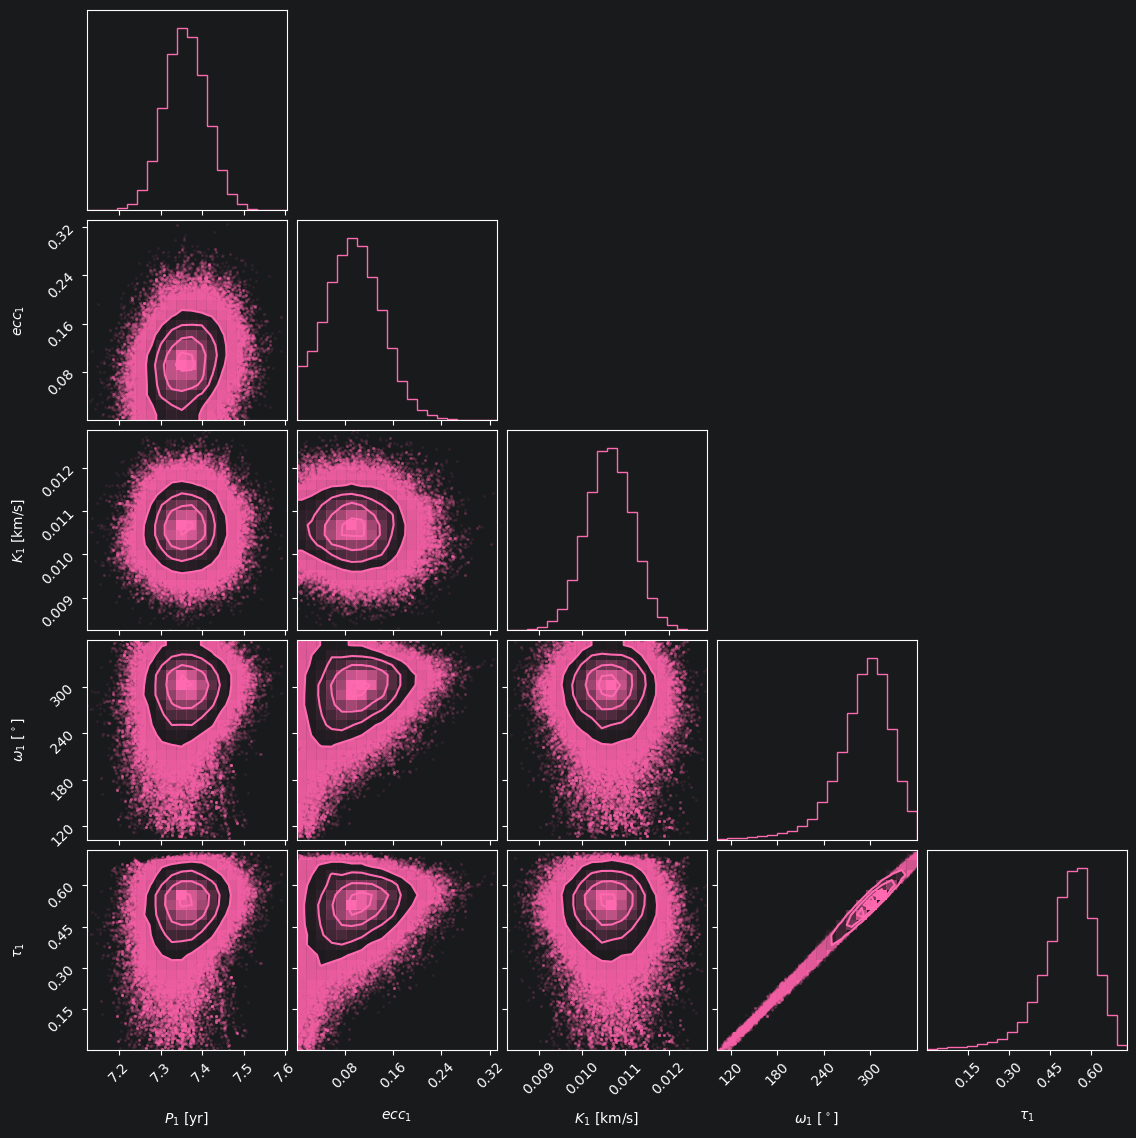

In [10]:
corner_figure = m.results.plot_corner( color="#FF69AF",
)
plt.show()

In [16]:
import sys
import importlib

repo_root = Path(DATADIR).resolve().parents[1]
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import simulate_dr4 as dr4_sim
importlib.reload(dr4_sim)

INJECTED_INC_DEG = 40.0
INJECTED_PAN_DEG = 186.0
DR4_REF_EPOCH_MJD = dr4_sim.DR4_REF_EPOCH_MJD

rv_system = m.system
rv_idx = rv_system.param_idx

if rv_system.fitting_basis != "SemiAmp":
    raise ValueError("This cell expects an RV fit in the SemiAmp basis.")
if m.results.post is None or len(m.results.post) == 0:
    raise RuntimeError("Complete the RV-only fit first.")

# Use one complete RV solution, preserving its parameter correlations.
best_index = np.nanargmax(m.results.lnlike)
truth_fit = np.asarray(m.results.post)[best_index].copy()

# RVs don't determine these: choose the mock's injected orientation.
truth_fit[rv_idx["inc1"]] = np.deg2rad(INJECTED_INC_DEG)
truth_fit[rv_idx["pan1"]] = np.deg2rad(INJECTED_PAN_DEG)

# Recompute mass and semimajor axis at the injected inclination.
truth_standard = rv_system.basis.to_standard_basis(truth_fit.copy())
standard_idx = rv_system.basis.standard_basis_idx

truth_params = {
    name: float(truth_standard[standard_idx[name]])
    for name in (
        "sma1", "ecc1", "inc1", "aop1", "pan1", "tau1",
        "plx", "m0", "m1",
    )
}

# These astrometric terms aren't supplied by the RV-only fit.
truth_params.update(
    alpha0=0.0,
    delta0=0.0,
    pm_ra=-974.758,
    pm_dec=20.876,
)

dr4_mock = dr4_sim.simulate_dr4(
    Path(DATADIR) / "eps_eri_gost_raw.csv",
    truth_params,
    g_mag=3.465752,
    seed=int(rng.integers(0, 2**32)),
    tau_ref_epoch=rv_system.tau_ref_epoch,
)

print(f"Simulated transits: {len(dr4_mock)}")
print(f"RV period: {truth_fit[rv_idx['per1']]:.3f} yr")
print(f"Injected i / LAN: {INJECTED_INC_DEG:g} / {INJECTED_PAN_DEG:g} deg")
print(f"Companion mass: {truth_params['m1'] * u.Msun.to(u.Mjup):.3f} Mjup")
dr4_mock[:5]

Simulated transits: 76
RV period: 7.391 yr
Injected i / LAN: 40 / 186 deg
Companion mass: 0.995 Mjup


source_id,transit_id,obs_time_tcb,parallax_factor_al,scan_pos_angle,field_of_view,centroid_pos_al,centroid_pos_error_al,ra_offset_al,quant_al,sigma_al
,,d,,rad,,mas,mas,,,
int64,int64,float64,float64,float64,str4,float64,float64,float64,float64,float64
0,0,56910.200194922276,-0.5706569277610049,-2.493845720157524,FoVF,-1783.7548892204097,0.1414213562373095,-1783.7548892204097,-1783.7548892204097,0.1414213562373095
0,1,56910.37636611005,-0.574313586713346,-2.4860633162509362,FoVP,-1802.0391740930863,0.1414213562373095,-1802.0391740930863,-1802.0391740930863,0.1414213562373095
0,2,57016.02494478831,0.3216342425606663,-1.141978177057848,FoVP,-2155.6445308625985,0.1414213562373095,-2155.6445308625985,-2155.6445308625985,0.1414213562373095
0,3,57016.09894705424,0.3192854060946805,-1.1372305369967584,FoVF,-2151.8296447580033,0.1414213562373095,-2151.8296447580033,-2151.8296447580033,0.1414213562373095
0,4,57035.10152081074,-0.5862368513432393,0.2017037733006469,FoVF,250.62270195968014,0.1414213562373095,250.62270195968014,250.62270195968014,0.1414213562373095


In [17]:
# Keep the completed RV fit separate
rv_system = m.system
rv_idx = rv_system.param_idx

if m.results.post is None or len(m.results.post) == 0:
    raise RuntimeError("Complete the RV-only fit first.")

rv_post = np.asarray(m.results.post)

# Mock OHP timestamps are JD(TCB); the reader converts them to MJD.
# Already an Astropy Table in MJD(TCB).
mock_table = dr4_mock.copy()

mock_gaia = gaia.DR4LogProb(
    0,
    mock_table,
    ref_epoch_mjd=DR4_REF_EPOCH_MJD,
    jitter_prior=priors.LogUniformPrior(1e-4, 1.0),
)

# Include the original RV measurements and the mock Gaia measurements.
joint_system = system.System(
    rv_system.num_secondary_bodies,
    rv_system.data_table.copy(),
    rv_system.stellar_or_system_mass,
    rv_system.plx,
    mass_err=rv_system.mass_err,
    plx_err=rv_system.plx_err,
    fit_secondary_mass=True,
    gaia=mock_gaia,
    tau_ref_epoch=rv_system.tau_ref_epoch,
    fitting_basis="SemiAmp",
)
joint_idx = joint_system.param_idx
for name, column in rv_idx.items():
    if name in joint_idx:
        joint_system.sys_priors[joint_idx[name]] = (
            rv_system.sys_priors[column]
        )

joint_mcmc = sampler.MCMC(
    joint_system,
    num_temps=num_temps,
    num_walkers=num_walkers,
    num_threads=num_threads,
)
sampled_idx = joint_mcmc.sampled_param_idx
positions = joint_mcmc.curr_pos.reshape(-1, joint_mcmc.num_params)

# RV posterior starting positions. inclination/LAN keep their prior draws.
warm_names = [
    name for name in sampled_idx
    if name in rv_idx and name not in ("inc1", "pan1")
]
rv_columns = [rv_idx[name] for name in warm_names]
joint_columns = [sampled_idx[name] for name in warm_names]

draws = rng.choice(len(rv_post), size=len(positions), replace=True)
positions[:, joint_columns] = rv_post[draws][:, rv_columns]

# Compute each trial stellar reflex orbit.
full_positions = joint_mcmc._fill_in_fixed_params(positions)
standard_positions = joint_system.basis.to_standard_basis(
    full_positions.T.copy()
)
ra, dec, _, _ = joint_system.compute_all_orbits(
    standard_positions, epochs=mock_gaia.epochs_mjd,
)
orbit_al = -(
    ra[:, 0, :] * mock_gaia.sin_scan[:, None]
    + dec[:, 0, :] * mock_gaia.cos_scan[:, None]
)

# Solve position/proper motion only to initialize the walkers.
# These parameters remain freely sampled during MCMC.
linear_columns = [
    sampled_idx[name]
    for name in ("alpha0", "delta0", "pm_ra", "pm_dec")
]

for walker, params in enumerate(full_positions):
    sigma = np.hypot(
        mock_gaia.centroid_pos_error_al,
        params[joint_idx["dr4_jitter"]],
    )
    target = (
        mock_gaia.centroid_pos_al
        - params[joint_idx["plx"]] * mock_gaia.parallax_factor_al
        - orbit_al[:, walker]
    )

    positions[walker, linear_columns] = gaia.HGCALogProb._linear_pm_fit(
        epochs=mock_gaia.dt_yr,
        raoff_planet=target * mock_gaia.sin_scan,
        decoff_planet=target * mock_gaia.cos_scan,
        epoch_ref_ra=0.0,
        epoch_ref_dec=0.0,
        sin_phi=mock_gaia.cos_scan,
        cos_phi=mock_gaia.sin_scan,
        errs=sigma,
    )

joint_mcmc.check_prior_support()

print(
    f"Joint data: {len(joint_system.data_table)} RVs "
    f"+ {mock_gaia.n_obs} Gaia transits"
)


Joint data: 693 RVs + 76 Gaia transits


In [18]:
# run sampler
joint_run = joint_mcmc.run_sampler(
    joint_mcmc.num_walkers * num_steps,
    burn_steps=burn_steps,
    thin=thin,
)
joint_post = joint_mcmc.results.post

print(f"Joint posterior samples: {len(joint_post)}")
print(
    f"Cold chain acceptance: "
    f"{np.mean(joint_run.acceptance_fraction[0]):.3f}"
)

Starting Burn in


/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:568: RuntimeWarning: invalid value encountered in log
  lnprob = np.log(np.sin(element_array) / normalization)
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: inv

2000/2000 steps of burn-in complete
Burn in complete. Sampling posterior now.
5000/5000 steps completed
Run complete
Joint posterior samples: 640000
Cold chain acceptance: 0.179


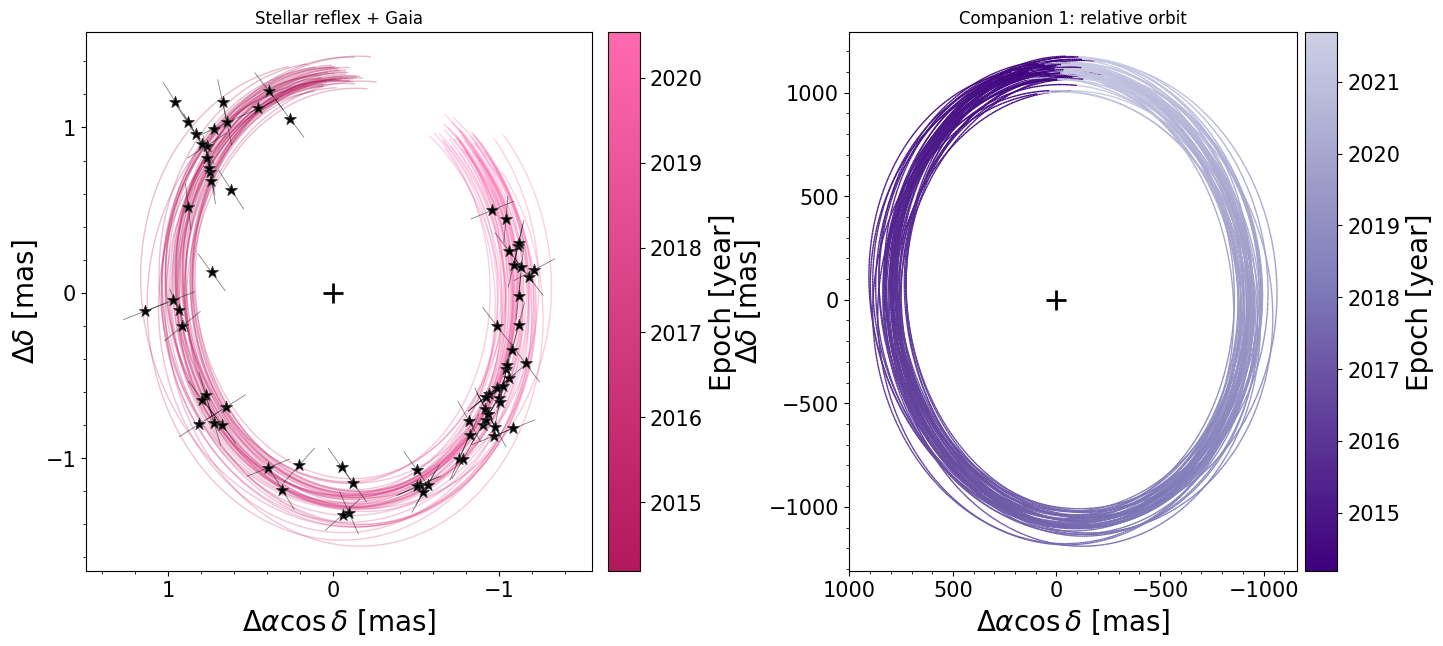

In [28]:
import importlib
import orbitize.plot as orbitize_plot

importlib.reload(orbitize_plot)

fig = joint_mcmc.results.plot_dr4_orbit(
    joint_mcmc.system,
    include_planet=True,
    planet_to_plot=1,
    num_orbits_to_plot=50,
    include_jitter=True,
)

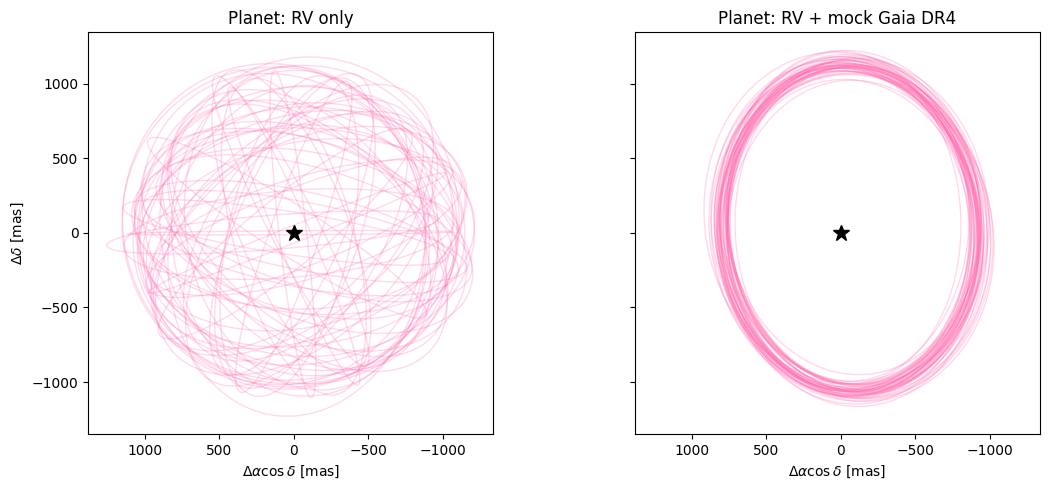

In [22]:
# PLOT PLANET ORBIT
rv_orbit_post = np.asarray(m.results.post)
joint_orbit_post = np.asarray(joint_mcmc.results.post)

rv_orbit_draws = rv_orbit_post[
    rng.choice(
        len(rv_orbit_post), size=min(50, len(rv_orbit_post)),
        replace=False,
    )
]
joint_orbit_draws = joint_orbit_post[
    rng.choice(
        len(joint_orbit_post), size=min(50, len(joint_orbit_post)),
        replace=False,
    )
]
with plt.style.context("default"):
    planet_fig, planet_axes = plt.subplots(
        1, 2, figsize=(12, 5), sharex=True, sharey=True,
    )

    for ax, orbit_system, orbit_draws, title in zip(
        planet_axes,
        [m.system, joint_mcmc.system],
        [rv_orbit_draws, joint_orbit_draws],
        ["Planet: RV only", "Planet: RV + mock Gaia DR4"],
    ):
        for draw in orbit_draws:
            standard = orbit_system.basis.to_standard_basis(draw.copy())
            period_days = 365.25 * draw[orbit_system.param_idx["per1"]]
            epochs = np.linspace(
                orbit_system.tau_ref_epoch,
                orbit_system.tau_ref_epoch + period_days,
                500,
            )
            ra, dec, _, _ = orbit_system.compute_all_orbits(
                standard, epochs=epochs,
            )

            # Body 1: planet–star separation, without reflex scaling.
            ax.plot(
                ra[:, 1, 0], dec[:, 1, 0],
                color="#FF69AF", alpha=0.25, lw=1,
            )

        ax.plot(0, 0, "*", color="black", ms=12)
        ax.set(
            title=title,
            xlabel=r"$\Delta\alpha\cos\delta$ [mas]",
        )
        ax.set_aspect("equal", adjustable="box")

    planet_axes[0].set_ylabel(r"$\Delta\delta$ [mas]")
    planet_axes[0].invert_xaxis()
    planet_fig.tight_layout()
    plt.show()

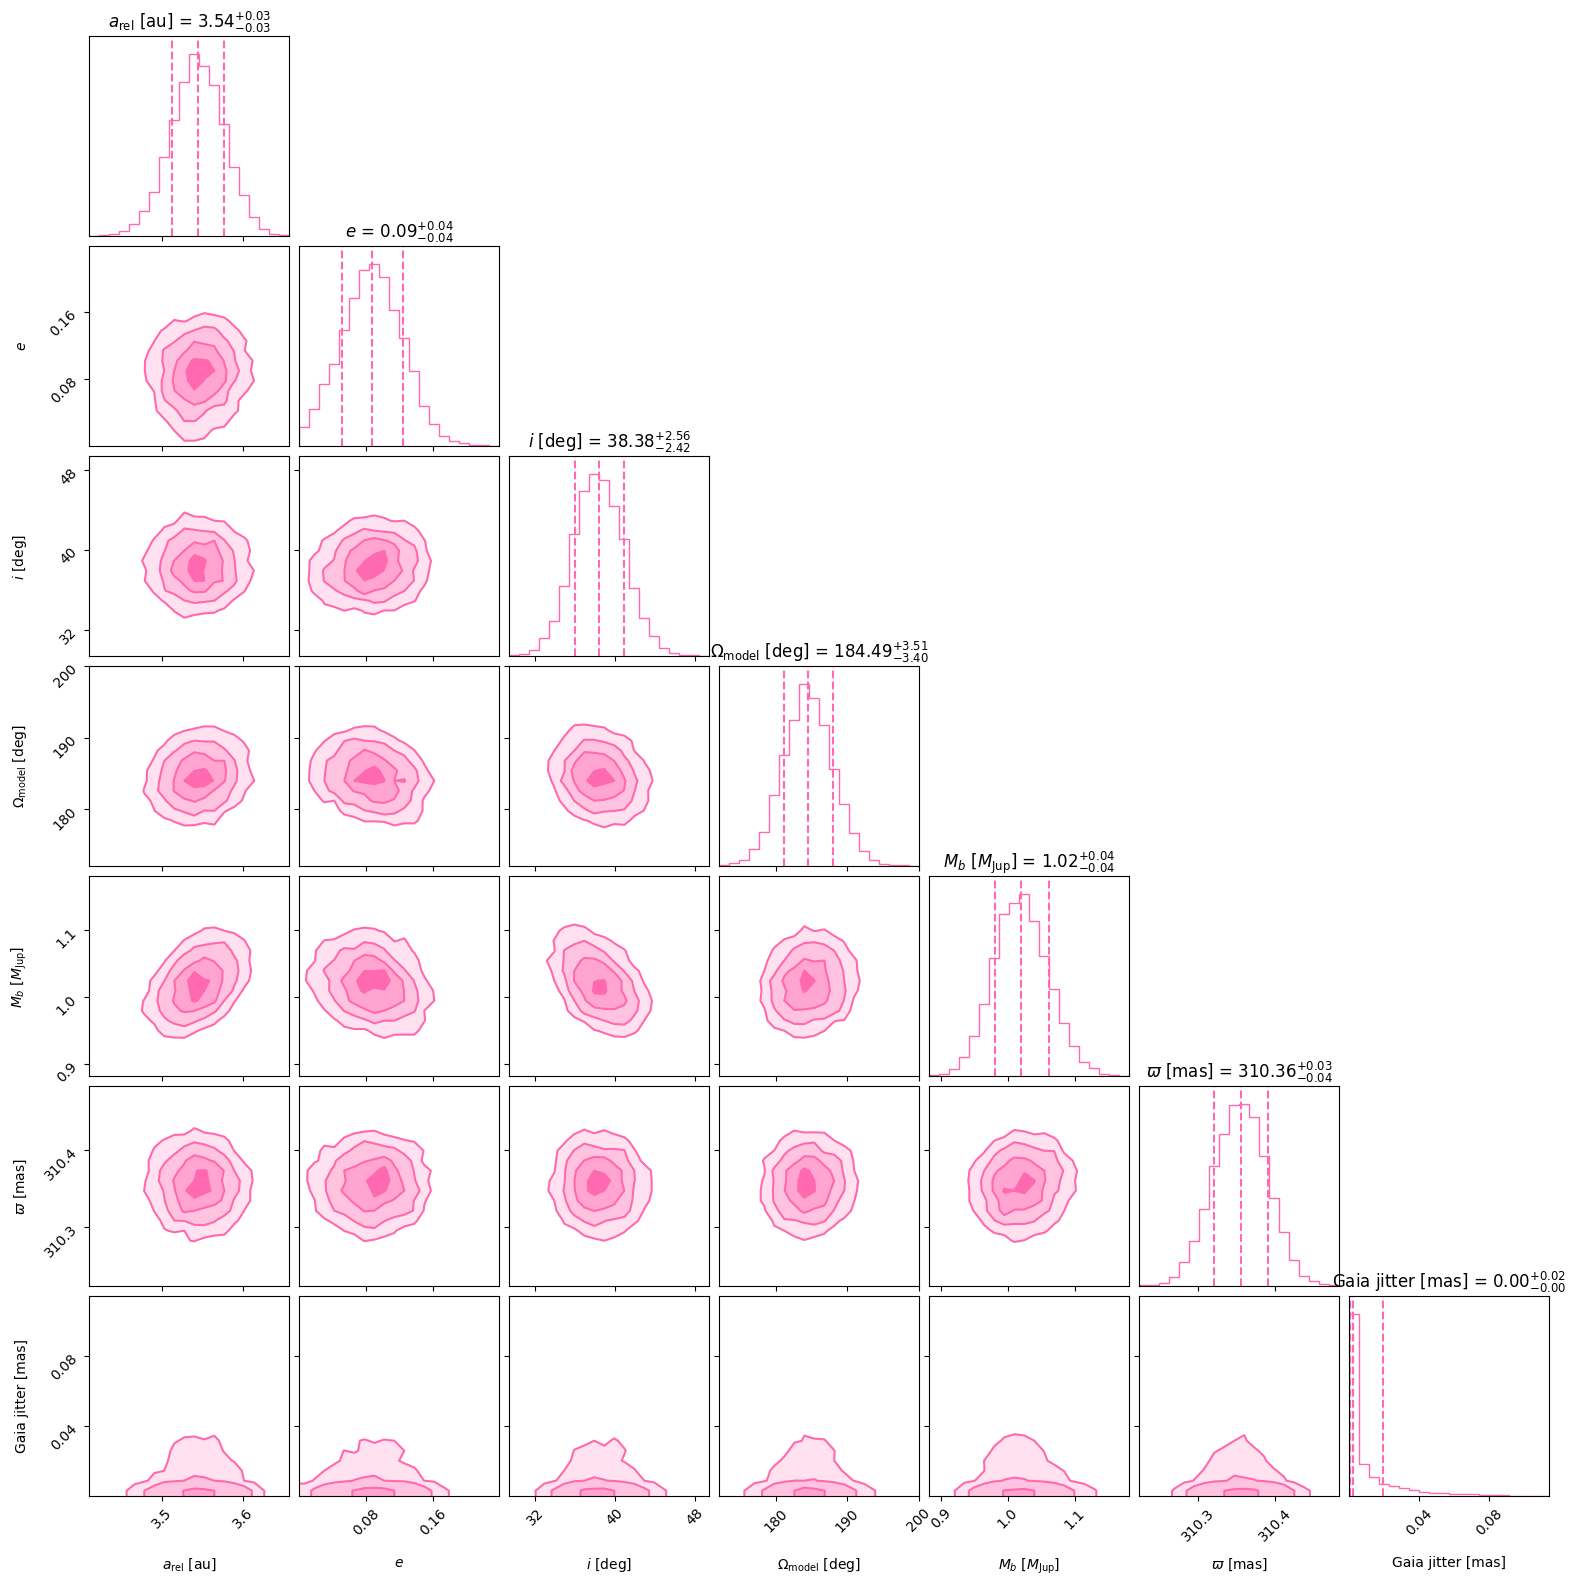

In [24]:

# final corner plot
from copy import copy

joint_results = joint_mcmc.results
plot_results = copy(joint_results)  #

draws = rng.choice(
    len(joint_results.post),
    size=min(20_000, len(joint_results.post)),
    replace=False,
)
basis = joint_mcmc.system.basis
plot_results.post = basis.to_standard_basis(
    joint_results.post[draws].T.copy()
).T
plot_results.lnlike = joint_results.lnlike[draws]
plot_results.param_idx = basis.standard_basis_idx.copy()

with plt.style.context("default"):
    corner_figure = plot_results.plot_corner(
        param_list=["sma1", "ecc1", "inc1", "pan1", "m1", "plx", "dr4_jitter"],
        labels=[
            r"$a_{\rm rel}$ [au]", r"$e$", r"$i$ [deg]",
            r"$\Omega_{\rm model}$ [deg]", r"$M_b$ [$M_{\rm Jup}$]",
            r"$\varpi$ [mas]", "Gaia jitter [mas]",
        ],
        color="#FF69AF",
        quantiles=[0.16, 0.5, 0.84],
        show_titles=True,
        plot_datapoints=False,
        fill_contours=True,
        max_n_ticks=3,
    )
    plt.show()

In [18]:
from copy import deepcopy

joint_system_1mas = deepcopy(joint_mcmc.system)
gaia_1mas = joint_system_1mas.gaia

# Update both the likelihood's errors and its stored data table.
gaia_1mas.centroid_pos_error_al[:] = 1.0
gaia_1mas.data_table["centroid_pos_error_al"][:] = 1.0

joint_mcmc_1mas = sampler.MCMC(
    joint_system_1mas,
    num_temps=joint_mcmc.num_temps,
    num_walkers=joint_mcmc.num_walkers,
    num_threads=joint_mcmc.num_threads,
)

# Start from the previous walkers, but run fresh burn-in and production.
joint_mcmc_1mas.curr_pos = joint_mcmc.curr_pos.copy()

run_1mas = joint_mcmc_1mas.run_sampler(
    joint_mcmc_1mas.num_walkers * num_steps,
    burn_steps=burn_steps,
    thin=thin,
)
post_1mas = joint_mcmc_1mas.results.post

print(f"Posterior samples: {len(post_1mas)}")
print(f"Cold acceptance: {np.mean(run_1mas.acceptance_fraction[0]):.3f}")

Starting Burn in


/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid value encountered in log
  lnprob = -np.log((element_array * normalizer))
/Users/clary/Projects/orbitize/orbitize/priors.py:417: RuntimeWarning: invalid val

2000/2000 steps of burn-in complete
Burn in complete. Sampling posterior now.
5000/5000 steps completed
Run complete
Posterior samples: 640000
Cold acceptance: 0.173


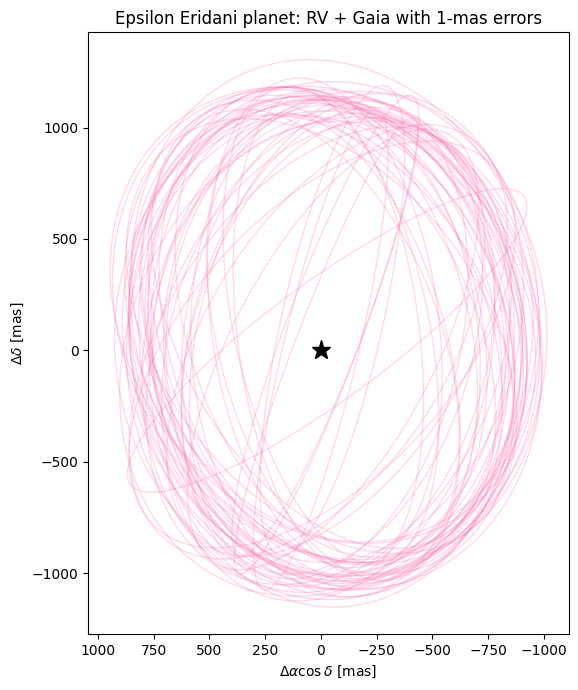

In [20]:
sys_1mas = joint_mcmc_1mas.system
post_1mas = joint_mcmc_1mas.results.post
planet_draws_1mas = rng.choice(
    len(post_1mas), min(50, len(post_1mas)), replace=False,
)

with plt.style.context("default"):
    planet_fig_1mas, planet_ax_1mas = plt.subplots(figsize=(7, 7))

    for index in planet_draws_1mas:
        draw = post_1mas[index]
        standard = sys_1mas.basis.to_standard_basis(draw.copy())
        period_days = 365.25 * draw[sys_1mas.param_idx["per1"]]
        epochs = np.linspace(
            sys_1mas.tau_ref_epoch,
            sys_1mas.tau_ref_epoch + period_days,
            500,
        )
        ra, dec, _, _ = sys_1mas.compute_all_orbits(
            standard, epochs=epochs,
        )
        planet_ax_1mas.plot(
            ra[:, 1, 0], dec[:, 1, 0],
            color="#FF69AF", alpha=0.25, lw=1,
        )

    planet_ax_1mas.plot(0, 0, "*", color="black", ms=14)
    planet_ax_1mas.set(
        xlabel=r"$\Delta\alpha\cos\delta$ [mas]",
        ylabel=r"$\Delta\delta$ [mas]",
        title="Epsilon Eridani planet: RV + Gaia with 1-mas errors",
    )
    planet_ax_1mas.set_aspect("equal", adjustable="box")
    planet_ax_1mas.invert_xaxis()
    planet_fig_1mas.tight_layout()
    plt.show()

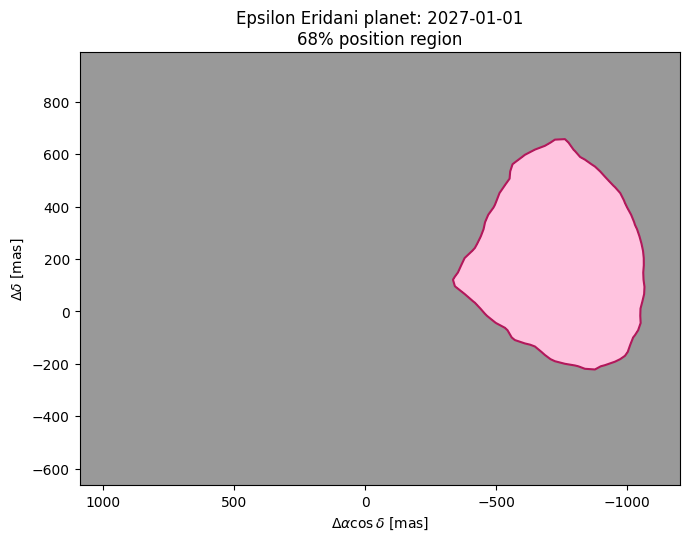

In [22]:
import corner
from astropy.time import Time

forecast_system = joint_mcmc_1mas.system
forecast_post = joint_mcmc_1mas.results.post

forecast_draws = rng.choice(
    len(forecast_post), min(20_000, len(forecast_post)), replace=False,
)
forecast_standard = forecast_system.basis.to_standard_basis(
    forecast_post[forecast_draws].T.copy()
)

# Convert UTC midnight to the TCB time scale used by the mock model.
forecast_epoch = Time("2027-01-01T00:00:00", scale="utc").tcb.mjd
forecast_ra, forecast_dec, _, _ = forecast_system.compute_all_orbits(
    forecast_standard, epochs=np.array([forecast_epoch]),
)

# Planet position relative to the host star, in mas.
x = forecast_ra[0, 1, :]
y = forecast_dec[0, 1, :]

with plt.style.context("default"):
    forecast_fig, forecast_ax = plt.subplots(figsize=(7, 7))
    corner.hist2d(
        x, y, ax=forecast_ax,
        bins=60, smooth=1, levels=[0.68],
        plot_datapoints=False,
        plot_density=False,
        fill_contours=True,
        color="#FF69AF",
        contourf_kwargs={"colors": ["none", "#FF69AF"], "alpha": 0.4},
        contour_kwargs={"colors": "#B2185B", "linewidths": 1.5},
    )
    forecast_ax.set(
        xlabel=r"$\Delta\alpha\cos\delta$ [mas]",
        ylabel=r"$\Delta\delta$ [mas]",
        title="Epsilon Eridani planet: 2027-01-01\n68% position region",
    )
    forecast_ax.set_aspect("equal", adjustable="box")
    forecast_ax.invert_xaxis()
    forecast_fig.tight_layout()
    plt.show()